# 01 · Data understanding

This notebook checks the EMNIST Digits data before modeling. It loads the saved train and test splits, inspects image and label distributions, and checks for duplicate images, blank images, and writer overlap.


In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Add project root to Python path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_emnist

In [2]:
(
    X_train,
    y_train,
    writers_train,
    X_test,
    y_test,
    writers_test,
) = load_emnist()

## Load and inspect the splits

The loader returns images, digit labels, and writer IDs for both splits. The first check confirms the number and shape of the examples.


In [3]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (240000, 28, 28)
y_train: (240000,)
X_test : (40000, 28, 28)
y_test : (40000,)


## Look at images and pixel values

A sample of images gives a visual check of the digit orientation and appearance. The pixel histogram shows how intensities are distributed before normalization.


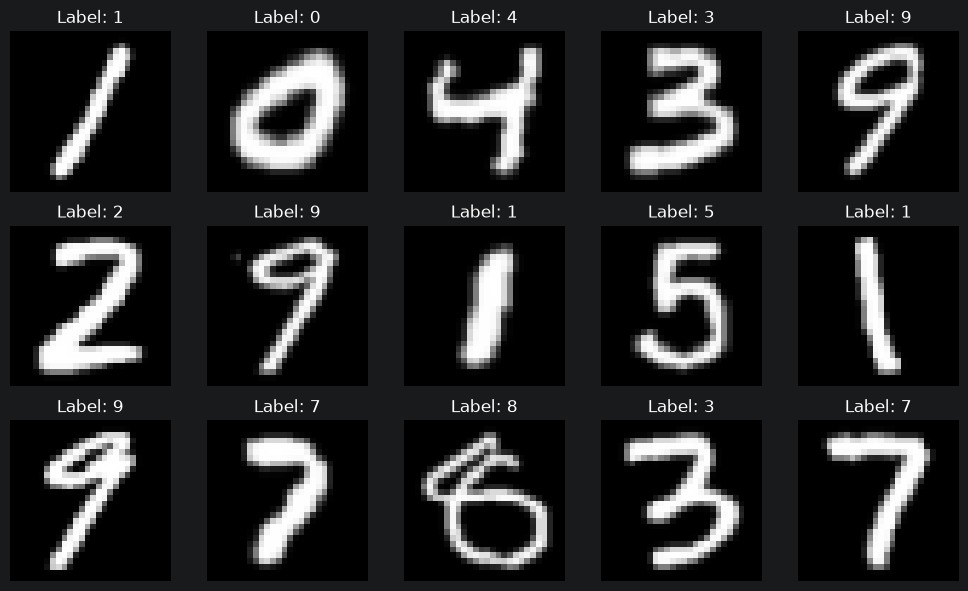

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6))

for ax in axes.ravel():

    idx = np.random.randint(len(X_train))

    ax.imshow(
        X_train[idx],
        cmap="gray"
    )

    ax.set_title(f"Label: {y_train[idx]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

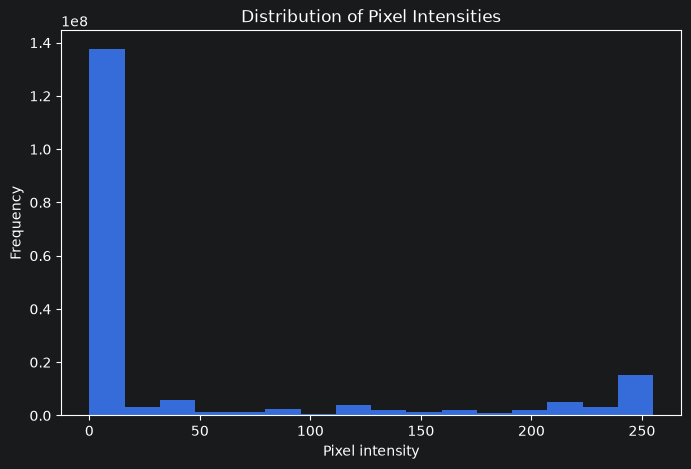

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(
    X_train.ravel(),
    bins=16
)

plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Intensities")

plt.show()

## Check class balance

Count each digit in the training split. A balanced label distribution makes raw accuracy easier to interpret.


In [6]:
classes, counts = np.unique(
    y_train,
    return_counts=True
)

for digit, count in zip(classes, counts):

    print(
        f"Digit {digit}: "
        f"{count:,} "
        f"({count / len(y_train):.2%})"
    )

Digit 0: 24,000 (10.00%)
Digit 1: 24,000 (10.00%)
Digit 2: 24,000 (10.00%)
Digit 3: 24,000 (10.00%)
Digit 4: 24,000 (10.00%)
Digit 5: 24,000 (10.00%)
Digit 6: 24,000 (10.00%)
Digit 7: 24,000 (10.00%)
Digit 8: 24,000 (10.00%)
Digit 9: 24,000 (10.00%)


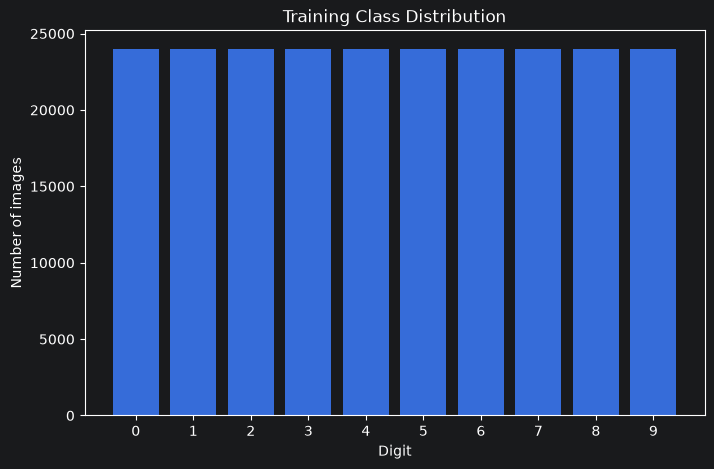

In [7]:
plt.figure(figsize=(8, 5))

plt.bar(classes, counts)

plt.xlabel("Digit")
plt.ylabel("Number of images")
plt.title("Training Class Distribution")

plt.xticks(classes)

plt.show()

## Check duplicates and empty images

These checks look for exact duplicate training images and images whose pixels are all zero.


In [8]:
X_flat = X_train.reshape(len(X_train), -1)

unique_images = np.unique(
    X_flat,
    axis=0
)

print("Total images :", len(X_flat))
print("Unique images:", len(unique_images))
print("Duplicates   :", len(X_flat) - len(unique_images))

Total images : 240000
Unique images: 240000
Duplicates   : 0


In [9]:
blank = np.all(
    X_train == 0,
    axis=(1, 2)
)

print("Blank images:", blank.sum())
print("Percentage  :", blank.mean())

Blank images: 0
Percentage  : 0.0


## Check writers across splits

Writer IDs help show whether the train and test sets contain distinct handwriting sources.


In [10]:
unique_writers, counts = np.unique(
    writers_train,
    return_counts=True
)

print("Number of writers:", len(unique_writers))

print("Images per writer")
print("-----------------")
print("Mean  :", counts.mean())
print("Median:", np.median(counts))
print("Min   :", counts.min())
print("Max   :", counts.max())

Number of writers: 3579
Images per writer
-----------------
Mean  : 67.05783738474435
Median: 69.0
Min   : 8
Max   : 125


In [11]:
train_writer_set = set(writers_train)
test_writer_set = set(writers_test)

overlap = train_writer_set & test_writer_set

print("Training writers:", len(train_writer_set))
print("Test writers    :", len(test_writer_set))
print("Overlap         :", len(overlap))

Training writers: 3579
Test writers    : 3577
Overlap         : 3577


## Findings

The saved output shows 240,000 training images and 40,000 test images, with 24,000 training examples for each digit. No exact duplicate or blank training images were found. The train and test sets share 3,577 writer IDs, so this split does not measure performance on entirely unseen writers.
